# Avaliação final · TEST · XGBoost e Random Forest

Avaliação solicitada pelo usuário após o desenvolvimento. Os dois artefatos,
features, calibrações e limiares estão fixados em `configs/test_evaluation.json`.
Não há treinamento, SMOTENC no TEST, busca de parâmetros ou ajuste de limiar neste notebook.
O pipeline aplica apenas transformações aprendidas no treino e `predict_proba`.
Machine failure=1 representa falha.

TEST corresponde aos UDI 8.001–10.000, reservado antes do desenvolvimento.
UDI não é timestamp verificado: este resultado não comprova antecipação de falha futura.
Após esta leitura, o TEST está revelado. Mudanças motivadas por seus resultados
precisam de outra amostra independente para confirmação final.


In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'configs/test_evaluation.json').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from predictive_maintenance.test_evaluation import evaluate_test, test_figures
from predictive_maintenance.presentation import readable_table

OUTPUT = evaluate_test(ROOT)
manifest = json.loads((OUTPUT / 'manifest.json').read_text(encoding='utf-8'))
def table(name):
    return pd.read_csv(OUTPUT / f'{name}.csv')
display(Markdown(f"**Snapshot:** `{OUTPUT.relative_to(ROOT)}` · **Registros:** {manifest['test_rows']} · **Falhas:** {manifest['positives']}"))
display(manifest['models'])
assert manifest['refit'] is False
assert manifest['threshold_tuning_on_test'] is False


**Snapshot:** `reports\test\test_b4b4cee2c103` · **Registros:** 2000 · **Falhas:** 39

{'xgboost': {'run_id': 'train_xgboost_20261101T001759Z_4c8d9ea9',
  'model_sha256': '3fabae724a15cbd8d4422f02a8a840187048347e352fe9a79da628b71a454797',
  'threshold': 0.815159689808473},
 'random_forest': {'run_id': 'train_random_forest_20261101T001858Z_680167a8',
  'model_sha256': 'a7b5911109a180bfbdc0f2c4262c08c9377ff876c2c1074b6acb6ccfdee39020',
  'threshold': 0.5}}

## Métricas completas e baseline

AP (Average Precision) e AUPRC trapezoidal são áreas diferentes e usam probabilidades.
Precisão, revocação, F1 e matriz de confusão usam o limiar de cada receita, escolhido antes do TEST.
Brier e log loss avaliam probabilidades; menores são melhores. O baseline prevê a prevalência
do bloco de ajuste do respectivo modelo e decide no limiar 0,5. Acurácia isolada é pouco
informativa com classes desbalanceadas. Valores indefinidos são apresentados como tal.
Em scores constantes do baseline, a integração trapezoidal interpola o segmento
entre os extremos e pode produzir área próxima de 0,5; AP é igual à prevalência
(1,95% neste TEST). Essa AUPRC do baseline não significa boa discriminação.


In [2]:
metrics = table('metrics')
display(readable_table(metrics[['model', 'n', 'positives', 'prevalence', 'threshold', 'ap', 'auprc', 'roc_auc', 'f1', 'recall', 'precision']]))
display(readable_table(metrics[['model', 'tn', 'fp', 'fn', 'tp', 'specificity', 'npv', 'fpr', 'fnr', 'alert_rate']]))
display(readable_table(metrics[['model', 'accuracy', 'balanced_accuracy', 'mcc', 'kappa', 'brier', 'log_loss']]))


,Receita,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,AP (score),AUPRC trapezoidal (score),ROC-AUC (score),F1 (%),Recall (%),Precision (%)
0,XGBoost,2.000,39,"1,95%","0,8152","0,7313","0,7306","0,9469","70,97%","56,41%","95,65%"
1,Random Forest,2.000,39,"1,95%","0,5000","0,7701","0,7696","0,9614","79,41%","69,23%","93,10%"
2,Baseline prior · XGBoost,2.000,39,"1,95%","0,5000","0,0195","0,5098","0,5000","0,00%","0,00%",Não definido
3,Baseline prior · Random Forest,2.000,39,"1,95%","0,5000","0,0195","0,5098","0,5000","0,00%","0,00%",Não definido


,Receita,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%)
0,XGBoost,1.960,1,17,22,"99,95%","99,14%","0,05%","43,59%","1,15%"
1,Random Forest,1.959,2,12,27,"99,90%","99,39%","0,10%","30,77%","1,45%"
2,Baseline prior · XGBoost,1.961,0,39,0,"100,00%","98,05%","0,00%","100,00%","0,00%"
3,Baseline prior · Random Forest,1.961,0,39,0,"100,00%","98,05%","0,00%","100,00%","0,00%"


,Receita,Acurácia (%),Acurácia balanceada (%),MCC,Kappa,Brier score,Log Loss
0,XGBoost,"99,10%","78,18%","0,7309","0,7054","0,0078","0,0432"
1,Random Forest,"99,30%","84,56%","0,7996","0,7906","0,0068","0,0369"
2,Baseline prior · XGBoost,"98,05%","50,00%",0,0,"0,0198","0,1062"
3,Baseline prior · Random Forest,"98,05%","50,00%",0,0,"0,0198","0,1062"


## Comparação com validação

Os modelos e limiares são os mesmos nas duas partições. Validação foi usada repetidamente
durante o desenvolvimento; TEST é a avaliação final desta receita. As populações e
prevalências podem diferir: uma diferença não isola uma causa nem prova superioridade estatística.


In [3]:
comparison = table('validation_test')
display(readable_table(comparison[['model', 'partition', 'n', 'positives', 'prevalence', 'threshold', 'ap', 'auprc', 'f1', 'recall', 'precision', 'fp', 'fn', 'brier']]))
for name, rows in comparison.groupby('model'):
    before = rows.loc[rows.partition.eq('VALIDATION')].iloc[0]
    final = rows.loc[rows.partition.eq('TEST')].iloc[0]
    display(Markdown(f"**{name}:** F1 {before.f1:.3f} → {final.f1:.3f}; AP {before.ap:.3f} → {final.ap:.3f}; "
                     f"no TEST: {int(final.tp)} falhas detectadas, {int(final.fn)} não detectadas e {int(final.fp)} falsos alertas."))


,Receita,Partição,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,AP (score),AUPRC trapezoidal (score),F1 (%),Recall (%),Precision (%),FP: falsos alertas,FN: falhas não detectadas,Brier score
0,XGBoost,Teste final,2.000,39,"1,95%","0,8152","0,7313","0,7306","70,97%","56,41%","95,65%",1,17,"0,0078"
1,XGBoost,Validação,1.600,35,"2,19%","0,8152","0,7624","0,7609","69,09%","54,29%","95,00%",1,16,"0,0097"
2,Random Forest,Teste final,2.000,39,"1,95%","0,5000","0,7701","0,7696","79,41%","69,23%","93,10%",2,12,"0,0068"
3,Random Forest,Validação,1.600,35,"2,19%","0,5000","0,8697","0,8691","85,25%","74,29%","100,00%",0,9,"0,0058"


**random_forest:** F1 0.852 → 0.794; AP 0.870 → 0.770; no TEST: 27 falhas detectadas, 12 não detectadas e 2 falsos alertas.

**xgboost:** F1 0.691 → 0.710; AP 0.762 → 0.731; no TEST: 22 falhas detectadas, 17 não detectadas e 1 falsos alertas.

## Matrizes, curvas PR/ROC, calibração e distribuição dos scores

Calibração no gráfico é apenas descritiva; nenhuma curva ajusta o modelo no TEST.
Histogramas usam eixo vertical simétrico logarítmico para exibir as duas classes.


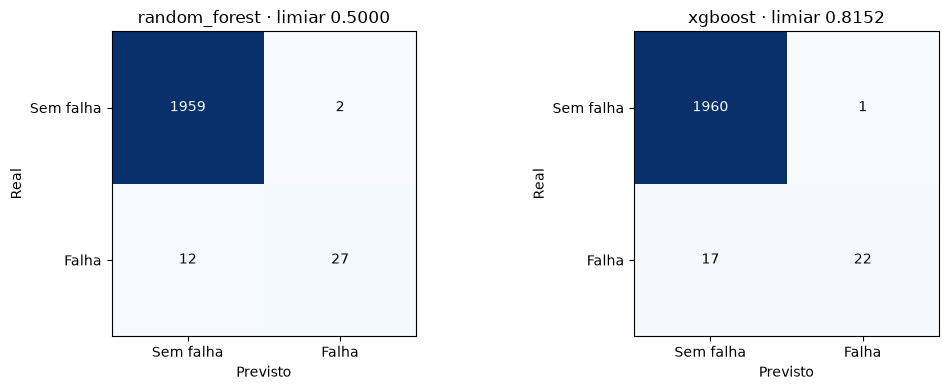

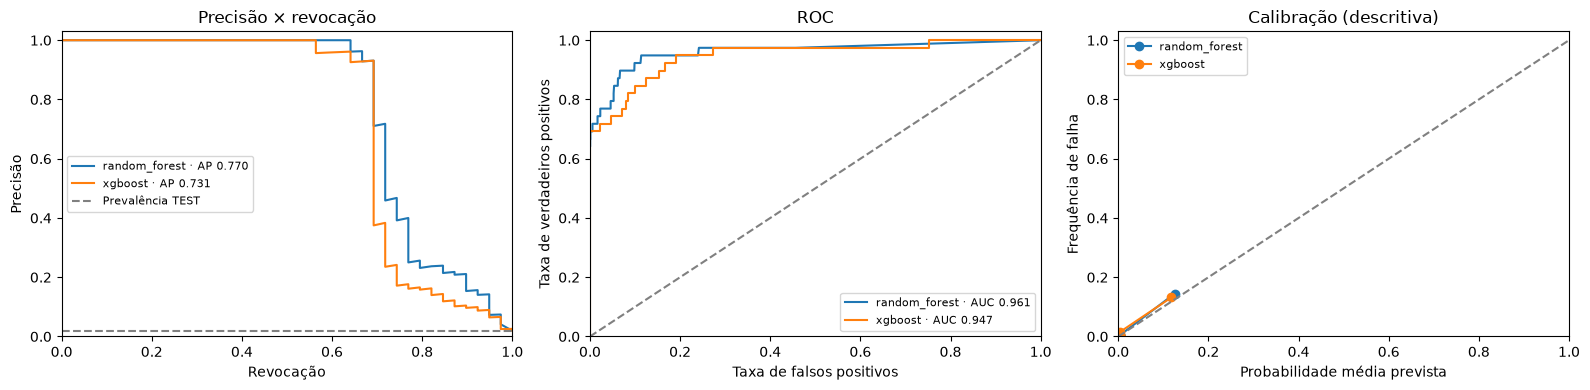

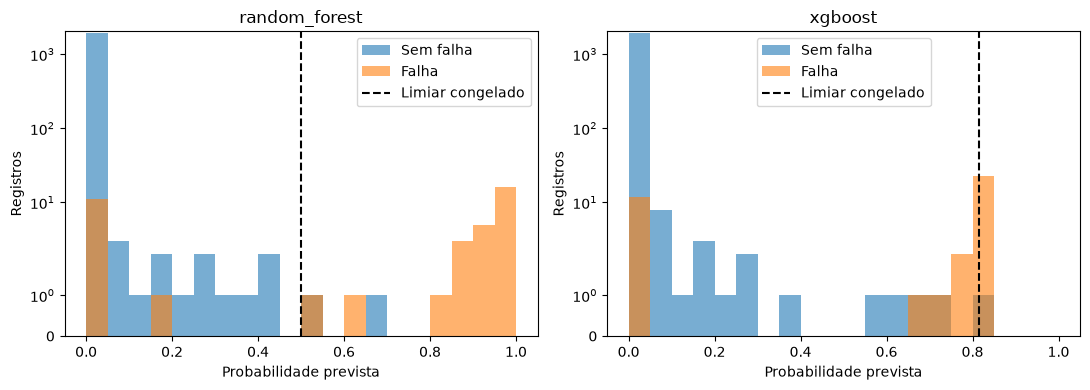

In [4]:
test_figures(OUTPUT)

## Relatório por classe e por tipo de produto

Os segmentos são diagnósticos descritivos, sem seleção de políticas por segmento.
Poucas falhas podem tornar as estimativas instáveis. O relatório por classe usa a convenção
do sklearn de zero para precisão/F1 indefinidos; a tabela principal preserva indefinidos.


In [5]:
classification = table('classification_report')
# A acurácia global já está na tabela principal; não é uma classe com suporte próprio.
display(readable_table(classification.loc[classification['class'].ne('accuracy')]))
display(readable_table(table('segments_type')))


,Classe / agregação,Precision (%),Recall (%),F1 (%),Observações da classe,Receita
0,Sem falha,"99,14%","99,95%","99,54%",1.961,XGBoost
1,Falha,"95,65%","56,41%","70,97%",39,XGBoost
3,Média macro,"97,40%","78,18%","85,26%",2.000,XGBoost
4,Média ponderada,"99,07%","99,10%","98,99%",2.000,XGBoost
5,Sem falha,"99,39%","99,90%","99,64%",1.961,Random Forest
6,Falha,"93,10%","69,23%","79,41%",39,Random Forest
8,Média macro,"96,25%","84,56%","89,53%",2.000,Random Forest
9,Média ponderada,"99,27%","99,30%","99,25%",2.000,Random Forest


,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa,Receita
0,Tipo,H,221,0,"0,00%","0,8152",221,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,Não definido,"0,0019","0,0106",Não definido,Não definido,XGBoost
1,Tipo,L,1.184,32,"2,70%","0,8152",1.151,1,12,20,"75,47%","62,50%","95,24%","99,91%","98,97%","0,09%","37,50%","1,77%","98,90%","81,21%","0,7261","0,7250","0,9438","0,0116","0,0618","0,7668","0,7493",XGBoost
2,Tipo,M,595,7,"1,18%","0,8152",588,0,5,2,"44,44%","28,57%","100,00%","100,00%","99,16%","0,00%","71,43%","0,34%","99,16%","64,29%","0,8669","0,8663","0,9769","0,0026","0,0182","0,5323","0,4415",XGBoost
3,Tipo,H,221,0,"0,00%","0,5000",220,1,0,0,"0,00%",Não definido,"0,00%","99,55%","100,00%","0,45%",Não definido,"0,45%","99,55%",Não definido,Não definido,Não definido,Não definido,"0,0028","0,0111",Não definido,Não definido,Random Forest
4,Tipo,L,1.184,32,"2,70%","0,5000",1.152,0,11,21,"79,25%","65,62%","100,00%","100,00%","99,05%","0,00%","34,38%","1,77%","99,07%","82,81%","0,7840","0,7834","0,9584","0,0091","0,0499","0,8063","0,7879",Random Forest
5,Tipo,M,595,7,"1,18%","0,5000",587,1,1,6,"85,71%","85,71%","85,71%","99,83%","99,83%","0,17%","14,29%","1,18%","99,66%","92,77%","0,8560","0,8532","0,9889","0,0039","0,0207","0,8554","0,8554",Random Forest


## Incerteza das métricas

Intervalos percentis de 95% com 500 reamostragens pareadas por registro, semente 42,
sem reajustar modelos. São aproximados e condicionais à receita já treinada.
Pressupõem registros independentes; dependência entre máquinas/ordem pode invalidá-los.
Não cobrem incerteza do treinamento nem demonstram diferença significativa entre modelos.


In [6]:
intervals = table('bootstrap_intervals')
intervals['metric'] = intervals['metric'].replace({'ap': 'AP', 'auprc': 'AUPRC trapezoidal', 'roc_auc': 'ROC-AUC', 'f1': 'F1', 'recall': 'Revocação', 'precision': 'Precisão', 'brier': 'Brier score'})
display(readable_table(intervals))


,Métrica,Limite inferior de 95% (escala 0–1),Limite superior de 95% (escala 0–1),Réplicas válidas,Receita
0,AP,"0,6028","0,8624",500,XGBoost
1,AUPRC trapezoidal,"0,6000","0,8617",500,XGBoost
2,ROC-AUC,"0,9038","0,9812",500,XGBoost
3,F1,"0,5737","0,8214",500,XGBoost
4,Revocação,"0,4110","0,7175",500,XGBoost
5,Precisão,"0,8696",1,500,XGBoost
6,Brier score,"0,0045","0,0113",500,XGBoost
7,AP,"0,6483","0,8815",500,Random Forest
8,AUPRC trapezoidal,"0,6463","0,8808",500,Random Forest
9,ROC-AUC,"0,9201","0,9897",500,Random Forest


## Artefatos e proveniência

CSV numéricos, previsões por UDI, composição do TEST, métricas por classe/Type,
comparação com validação, intervalos e figuras ficam no snapshot em `reports/test/`.
O manifesto registra hashes do dataset, modelos e tabelas, além dos limiares originais.
Reexecutar o notebook reutiliza os resultados e verifica sua integridade.
Os manifestos originais de treinamento permanecem como registro histórico anterior ao TEST.


In [7]:
display(manifest)

{'settings': {'runs': {'xgboost': 'train_xgboost_20261101T001759Z_4c8d9ea9',
   'random_forest': 'train_random_forest_20261101T001858Z_680167a8'},
  'seed': 42,
  'bootstrap_repeats': 500},
 'config_sha256': 'b4b4cee2c103e45fd66fb9cb2a24acda64faf399dd8c4746a5b4294f15a44601',
 'dataset_sha256': 'dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e',
 'models': {'xgboost': {'run_id': 'train_xgboost_20261101T001759Z_4c8d9ea9',
   'model_sha256': '3fabae724a15cbd8d4422f02a8a840187048347e352fe9a79da628b71a454797',
   'threshold': 0.815159689808473},
  'random_forest': {'run_id': 'train_random_forest_20261101T001858Z_680167a8',
   'model_sha256': 'a7b5911109a180bfbdc0f2c4262c08c9377ff876c2c1074b6acb6ccfdee39020',
   'threshold': 0.5}},
 'evaluated_at_utc': '2026-11-02T22:03:12.668277+00:00',
 'test_rows': 2000,
 'positives': 39,
 'test_evaluated': True,
 'refit': False,
 'threshold_tuning_on_test': False,
 'code_sha256': '9e2b14cd915ff5741e5e8240ded809a5250907fc3e718ebec2c3b8debd